# Implementation and Time Analysis of the Floyd-Warshall Algorithm (All-Pairs Shortest Paths)

**Problem:** Given a weighted, **directed** graph, find the shortest path
distance between **every pair** of vertices (not just from a single source).

**Floyd-Warshall (dynamic programming):** let `dist[i][j]` be the shortest known
distance from `i` to `j`. For each vertex `k`, in turn, ask: *"would going from
`i` to `j` **through `k`** be shorter than the best path found so far?"*

```
dist[i][j] = min( dist[i][j],  dist[i][k] + dist[k][j] )
```

After processing `k = 0, 1, ..., V-1`, `dist[i][j]` is the true shortest distance
using any intermediate vertices.

This notebook covers:
- The algorithm with a **next-hop matrix** so the actual shortest *paths* can be reconstructed, not just distances
- User input (enter your own directed weighted edges)
- Runtime measurement, time complexity, and space complexity
- A step-by-step view of how the matrix changes after each `k`
- **Negative edge weights** and **negative cycle detection**
- Visualizations: the graph and a heatmap of the distance matrix
- Verification against `networkx`
- A runtime comparison: Floyd-Warshall vs running Dijkstra from every vertex


In [1]:
# Common imports used throughout the notebook
import time
import heapq
import random
from collections import defaultdict
import matplotlib.pyplot as plt
import networkx as nx

INF = float('inf')


def get_user_edges(demo_string=None):
    """Takes DIRECTED weighted edges as 'u,v,w' triples separated by semicolons.

    Example: A,B,3;B,C,2;C,A,5   -> edges A->B (3), B->C (2), C->A (5)

    - Interactive use: call get_user_edges() with NO arguments to be prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own graph.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter directed edges as u,v,weight separated by semicolons (e.g., A,B,3;B,C,2;C,A,5): "
    )
    edges = []
    try:
        for triple in raw.split(';'):
            triple = triple.strip()
            if not triple:
                continue
            u, v, w = [x.strip() for x in triple.split(',')]
            edges.append((u, v, int(w)))
        if not edges:
            raise ValueError
    except ValueError:
        print("Invalid input detected, using a default sample graph instead.")
        edges = [('A', 'B', 3), ('A', 'D', 7), ('B', 'A', 8), ('B', 'C', 2),
                 ('C', 'A', 5), ('C', 'D', 1), ('D', 'A', 2)]
    return edges


def nodes_from_edges(edges):
    seen = []
    for u, v, _ in edges:
        for x in (u, v):
            if x not in seen:
                seen.append(x)
    return sorted(seen)


def print_matrix(matrix, nodes, title=""):
    if title:
        print(title)
    header = "      " + "".join(f"{n:>6}" for n in nodes)
    print(header)
    for i, n in enumerate(nodes):
        row = f"{n:>5} "
        for j in range(len(nodes)):
            val = matrix[i][j]
            row += f"{'INF':>6}" if val == INF else f"{val:>6}"
        print(row)


## 1. The Algorithm

**Setup:**
- `dist[i][i] = 0` (distance from a vertex to itself)
- `dist[i][j] = w` if there is a direct edge `i -> j` of weight `w` (keep the smaller one if there are parallel edges)
- `dist[i][j] = INF` otherwise

We also keep `nxt[i][j]` = the **first vertex after `i`** on the shortest path to
`j`. Whenever we find a shorter route through `k`, the first step toward `j`
becomes the first step toward `k`: `nxt[i][j] = nxt[i][k]`. Following `nxt`
repeatedly from `i` walks the whole shortest path.

**Three nested loops** (the order matters — `k` must be the **outermost** loop):
```
for k in vertices:          # allowed intermediate vertex
    for i in vertices:      # source
        for j in vertices:  # destination
            if dist[i][k] + dist[k][j] < dist[i][j]: update
```


In [2]:
def floyd_warshall(nodes, edges, verbose=False):
    """Returns (dist, nxt) matrices indexed by position in `nodes`."""
    n = len(nodes)
    idx = {node: i for i, node in enumerate(nodes)}

    dist = [[INF] * n for _ in range(n)]
    nxt = [[None] * n for _ in range(n)]

    for i in range(n):
        dist[i][i] = 0

    for u, v, w in edges:
        i, j = idx[u], idx[v]
        if w < dist[i][j]:          # keep the cheapest of any parallel edges
            dist[i][j] = w
            nxt[i][j] = j

    for k in range(n):
        changed = False
        for i in range(n):
            if dist[i][k] == INF:
                continue            # no path i -> k, so k can't help i
            for j in range(n):
                if dist[k][j] == INF:
                    continue
                new_dist = dist[i][k] + dist[k][j]
                if new_dist < dist[i][j]:
                    dist[i][j] = new_dist
                    nxt[i][j] = nxt[i][k]
                    changed = True
        if verbose:
            print_matrix(dist, nodes, f"\nAfter allowing '{nodes[k]}' as an intermediate vertex"
                                      f"{'' if changed else ' (no change)'}:")

    return dist, nxt


In [3]:
def has_negative_cycle(dist):
    """After Floyd-Warshall, a negative value on the diagonal means a negative cycle."""
    return any(dist[i][i] < 0 for i in range(len(dist)))


def reconstruct_path(nodes, nxt, dist, source, target):
    """Returns the shortest path from source to target as a list of node names, or None."""
    idx = {node: i for i, node in enumerate(nodes)}
    i, j = idx[source], idx[target]
    if dist[i][j] == INF:
        return None
    path = [source]
    while i != j:
        i = nxt[i][j]
        path.append(nodes[i])
    return path


## 2. Floyd-Warshall: User Input + Runtime

In [4]:
# Replace the argument below with nothing, i.e. get_user_edges(),
# to type your own directed weighted graph interactively.
edges = get_user_edges("A,B,3;A,D,7;B,A,8;B,C,2;C,A,5;C,D,1;D,A,2")
nodes = nodes_from_edges(edges)

print("Directed edges (u -> v, weight):")
for u, v, w in edges:
    print(f"  {u} -> {v}  ({w})")

# Show the starting matrix (before any intermediate vertex is allowed)
start_dist = [[INF] * len(nodes) for _ in nodes]
idx = {n: i for i, n in enumerate(nodes)}
for i in range(len(nodes)):
    start_dist[i][i] = 0
for u, v, w in edges:
    start_dist[idx[u]][idx[v]] = min(start_dist[idx[u]][idx[v]], w)
print()
print_matrix(start_dist, nodes, "Initial distance matrix (direct edges only):")

t0 = time.time()
dist, nxt = floyd_warshall(nodes, edges)
t1 = time.time()

print()
print_matrix(dist, nodes, "FINAL shortest-distance matrix (all pairs):")
print(f"\nNegative cycle detected: {has_negative_cycle(dist)}")
print(f"Runtime: {(t1 - t0) * 1000:.6f} ms")


Directed edges (u -> v, weight):
  A -> B  (3)
  A -> D  (7)
  B -> A  (8)
  B -> C  (2)
  C -> A  (5)
  C -> D  (1)
  D -> A  (2)

Initial distance matrix (direct edges only):
           A     B     C     D
    A      0     3   INF     7
    B      8     0     2   INF
    C      5   INF     0     1
    D      2   INF   INF     0

FINAL shortest-distance matrix (all pairs):
           A     B     C     D
    A      0     3     5     6
    B      5     0     2     3
    C      3     6     0     1
    D      2     5     7     0

Negative cycle detected: False
Runtime: 0.036716 ms


In [5]:
# --- Reconstruct some actual shortest paths ---
pairs = [('A', 'C'), ('A', 'D'), ('B', 'D'), ('D', 'C')]
print("Sample shortest paths:")
for s, t in pairs:
    if s in nodes and t in nodes:
        path = reconstruct_path(nodes, nxt, dist, s, t)
        d = dist[nodes.index(s)][nodes.index(t)]
        if path is None:
            print(f"  {s} -> {t}: unreachable")
        else:
            print(f"  {s} -> {t}: {' -> '.join(path)}   (distance {d})")


Sample shortest paths:
  A -> C: A -> B -> C   (distance 5)
  A -> D: A -> B -> C -> D   (distance 6)
  B -> D: B -> C -> D   (distance 3)
  D -> C: D -> A -> B -> C   (distance 7)


**Time Complexity:** `O(V^3)` — three nested loops over all `V` vertices.
This is the same for best, average, and worst case (the loops always run in full).

**Space Complexity:** `O(V^2)` — for the `dist` and `nxt` matrices.

Because every vertex is tried as an intermediate stop for every pair, it also
works with **negative edge weights** (unlike Dijkstra's algorithm) as long as
there is no negative cycle.


## 3. Step-by-Step: How the Matrix Evolves

With `verbose=True`, we print the distance matrix after each vertex `k` has been
allowed as an intermediate stop. Watch the `INF` entries get filled in and the
numbers shrink as better routes are discovered.


In [6]:
_ = floyd_warshall(nodes, edges, verbose=True)


After allowing 'A' as an intermediate vertex:
           A     B     C     D
    A      0     3   INF     7
    B      8     0     2    15
    C      5     8     0     1
    D      2     5   INF     0

After allowing 'B' as an intermediate vertex:
           A     B     C     D
    A      0     3     5     7
    B      8     0     2    15
    C      5     8     0     1
    D      2     5     7     0

After allowing 'C' as an intermediate vertex:
           A     B     C     D
    A      0     3     5     6
    B      7     0     2     3
    C      5     8     0     1
    D      2     5     7     0

After allowing 'D' as an intermediate vertex:
           A     B     C     D
    A      0     3     5     6
    B      5     0     2     3
    C      3     6     0     1
    D      2     5     7     0


## 4. Negative Edges and Negative Cycle Detection

**Negative edges** are fine for Floyd-Warshall. A **negative cycle** (a loop whose
total weight is negative) is a problem: you could go around it forever and make
the "shortest" distance arbitrarily small, so shortest paths are undefined for
anything that can reach it. Floyd-Warshall detects this: after it finishes, if
any `dist[i][i] < 0`, a negative cycle exists.


In [7]:
# --- Graph WITH a negative edge but NO negative cycle ---
neg_edges = [('A', 'B', 4), ('A', 'C', 5), ('B', 'D', -3), ('C', 'D', 2), ('D', 'E', 2)]
neg_nodes = nodes_from_edges(neg_edges)
neg_dist, neg_nxt = floyd_warshall(neg_nodes, neg_edges)

print("Graph with a negative edge (B -> D has weight -3), no negative cycle")
print_matrix(neg_dist, neg_nodes, "Shortest distances:")
print("Negative cycle detected:", has_negative_cycle(neg_dist))
path = reconstruct_path(neg_nodes, neg_nxt, neg_dist, 'A', 'E')
print("Shortest path A -> E:", " -> ".join(path), f"(distance {neg_dist[0][neg_nodes.index('E')]})")

# --- Graph WITH a negative cycle ---
cycle_edges = [('A', 'B', 1), ('B', 'C', -3), ('C', 'A', 1), ('C', 'D', 2)]
cycle_nodes = nodes_from_edges(cycle_edges)
cycle_dist, _ = floyd_warshall(cycle_nodes, cycle_edges)

print("\nGraph with a negative cycle: A -> B -> C -> A has total weight 1 + (-3) + 1 = -1")
print("Negative cycle detected:", has_negative_cycle(cycle_dist))
print("Diagonal entries (negative = vertex lies on a negative cycle, or on a cycle through one):",
      {cycle_nodes[i]: cycle_dist[i][i] for i in range(len(cycle_nodes))})
print("Note: once a negative cycle exists, the other distances are NOT meaningful - "
      "a program should report the cycle and stop.")


Graph with a negative edge (B -> D has weight -3), no negative cycle
Shortest distances:
           A     B     C     D     E
    A      0     4     5     1     3
    B    INF     0   INF    -3    -1
    C    INF   INF     0     2     4
    D    INF   INF   INF     0     2
    E    INF   INF   INF   INF     0
Negative cycle detected: False
Shortest path A -> E: A -> B -> D -> E (distance 3)

Graph with a negative cycle: A -> B -> C -> A has total weight 1 + (-3) + 1 = -1
Negative cycle detected: True
Diagonal entries (negative = vertex lies on a negative cycle, or on a cycle through one): {'A': -1, 'B': -1, 'C': -2, 'D': 0}
Note: once a negative cycle exists, the other distances are NOT meaningful - a program should report the cycle and stop.


## 5. Visualizations

Left: the directed graph with edge weights. Right: a heatmap of the final
all-pairs distance matrix (rows = source, columns = destination; unreachable
pairs are left blank).


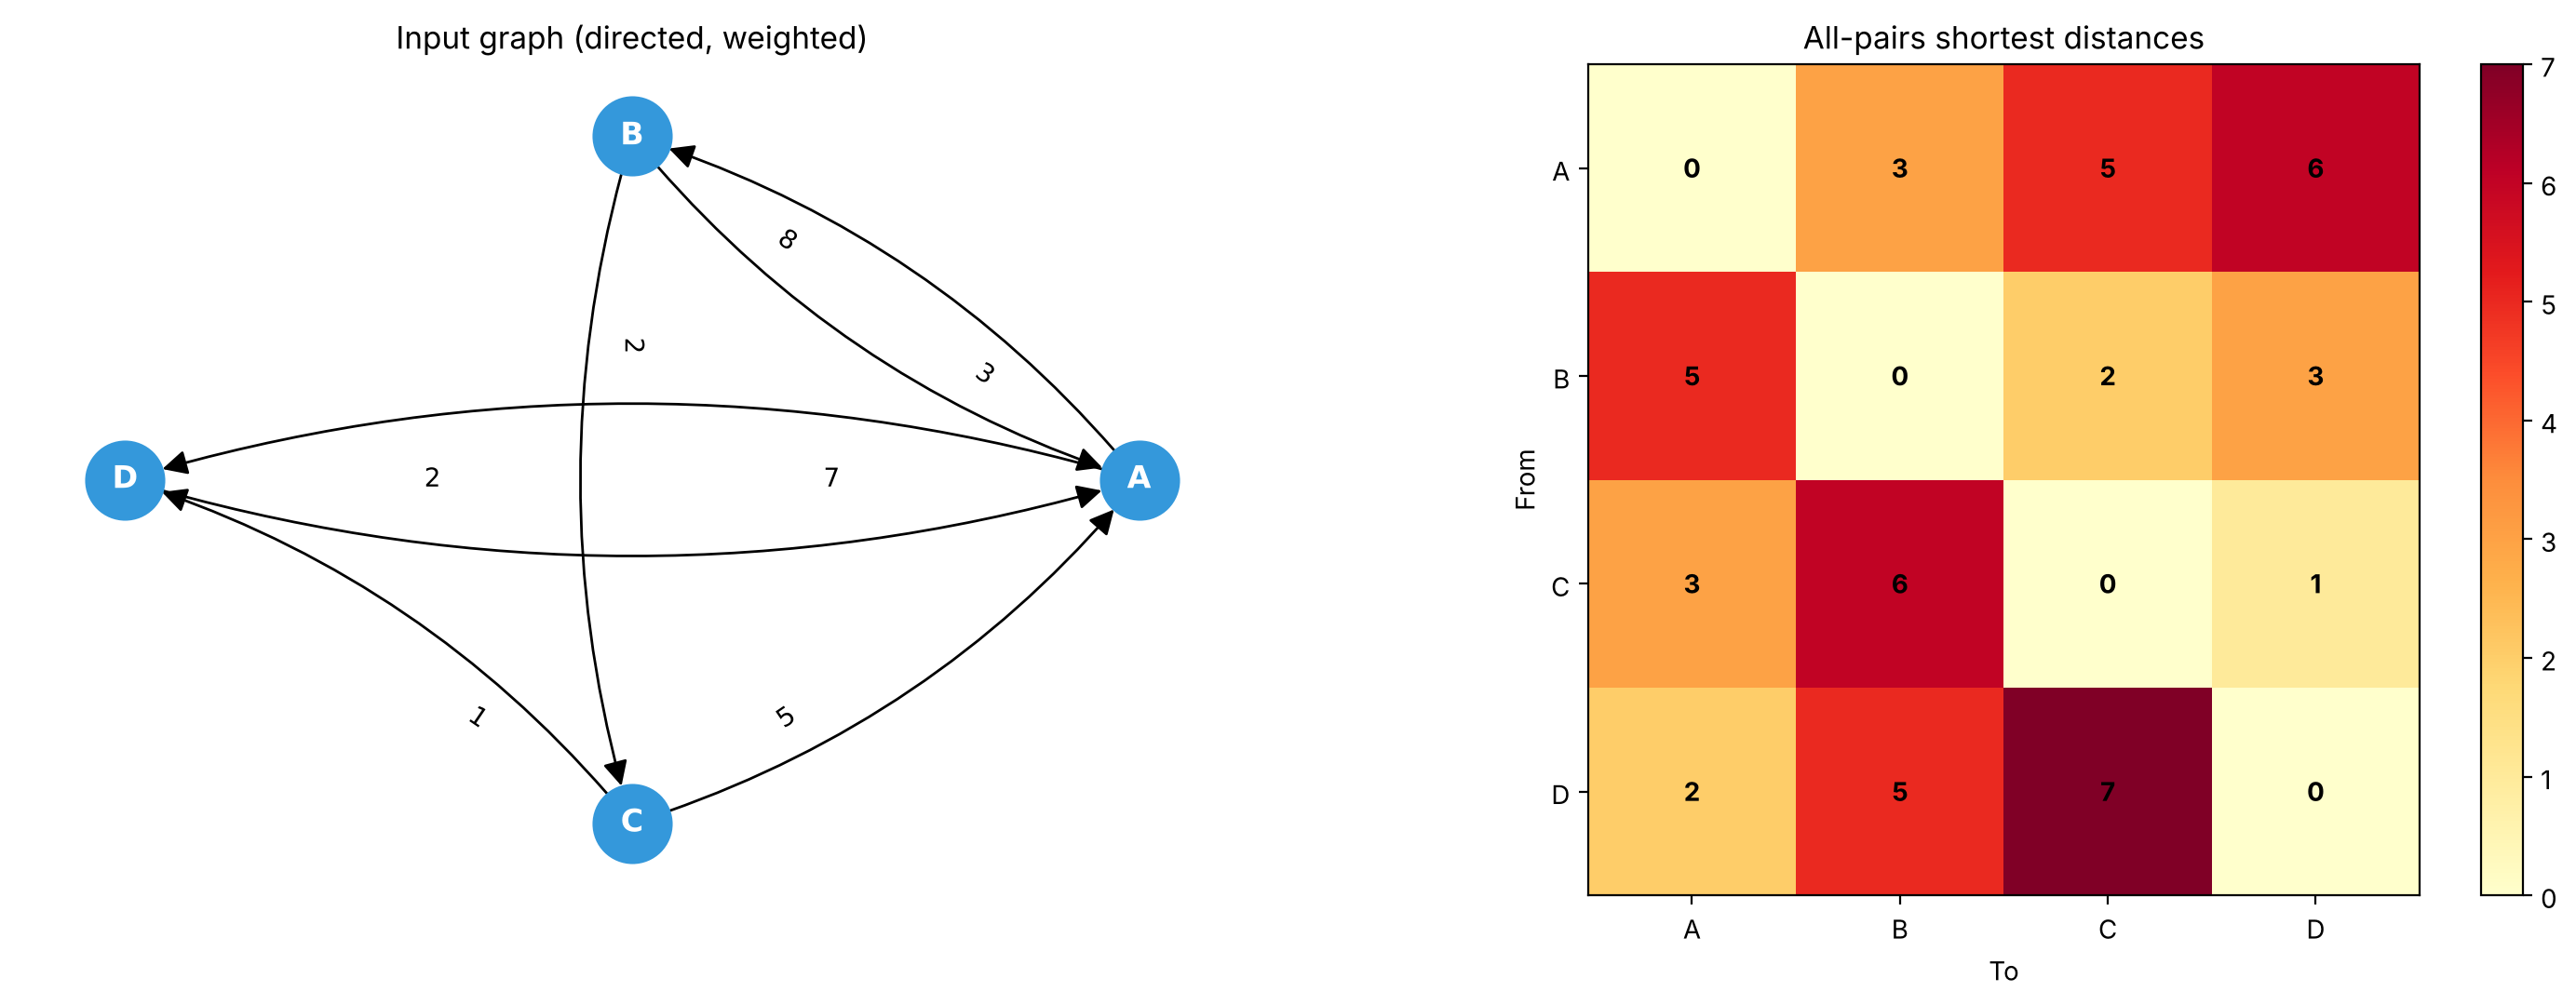

In [8]:
G = nx.DiGraph()
for u, v, w in edges:
    G.add_edge(u, v, weight=w)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left: directed graph ---
pos = nx.circular_layout(G)
nx.draw_networkx_nodes(G, pos, node_color='#3498db', node_size=900, ax=axes[0])
nx.draw_networkx_labels(G, pos, font_color='white', font_weight='bold', ax=axes[0])
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=20, node_size=900,
                       connectionstyle='arc3,rad=0.15', ax=axes[0])
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'weight'),
                             label_pos=0.3, ax=axes[0])
axes[0].set_title("Input graph (directed, weighted)")
axes[0].axis('off')

# --- Right: heatmap of dist matrix ---
import numpy as np
matrix = np.array([[v if v != INF else np.nan for v in row] for row in dist], dtype=float)
im = axes[1].imshow(matrix, cmap='YlOrRd')
axes[1].set_xticks(range(len(nodes))); axes[1].set_xticklabels(nodes)
axes[1].set_yticks(range(len(nodes))); axes[1].set_yticklabels(nodes)
axes[1].set_xlabel("To"); axes[1].set_ylabel("From")
axes[1].set_title("All-pairs shortest distances")
for i in range(len(nodes)):
    for j in range(len(nodes)):
        if not np.isnan(matrix[i][j]):
            axes[1].text(j, i, int(matrix[i][j]), ha='center', va='center', fontweight='bold')
fig.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()


## 6. Verification against `networkx`

We compare every entry of our distance matrix with `networkx`'s own
`floyd_warshall` on the demo graph, and also on a larger random graph.


In [9]:
def matches_networkx(nodes, edges, our_dist):
    G = nx.DiGraph()
    G.add_nodes_from(nodes)
    for u, v, w in edges:
        if G.has_edge(u, v):
            w = min(w, G[u][v]['weight'])   # parallel edges: keep the cheapest
        G.add_edge(u, v, weight=w)
    nx_dist = nx.floyd_warshall(G, weight='weight')
    for i, a in enumerate(nodes):
        for j, b in enumerate(nodes):
            if our_dist[i][j] != nx_dist[a][b]:
                return False
    return True

print("Demo graph matches networkx:", matches_networkx(nodes, edges, dist))

random.seed(1)
rand_nodes = list(range(30))
rand_edges = [(random.randrange(30), random.randrange(30), random.randint(1, 20)) for _ in range(120)]
rand_edges = [(u, v, w) for u, v, w in rand_edges if u != v]
rand_dist, _ = floyd_warshall(rand_nodes, rand_edges)
print("Random 30-node graph matches networkx:", matches_networkx(rand_nodes, rand_edges, rand_dist))


Demo graph matches networkx: True
Random 30-node graph matches networkx: True


## 7. Runtime Comparison: Floyd-Warshall vs Dijkstra from Every Vertex

Another way to get all-pairs shortest paths (when all weights are **non-negative**)
is to run Dijkstra's algorithm once from every vertex, costing `O(V * E log V)`.
- **Sparse graphs** (`E ~ 3V`): `V * E log V` is roughly `V^2 log V`, which should clearly beat Floyd-Warshall's `V^3`
- **Dense graphs** (`E ~ V^2 / 2`): `V * E log V` approaches `V^3 log V`, so on paper Floyd-Warshall should become competitive

The experiment below checks whether that holds in practice (all weights are non-negative, so both methods apply).


In [10]:
def dijkstra_all_pairs(num_nodes, edge_list):
    adj = defaultdict(list)
    for u, v, w in edge_list:
        adj[u].append((v, w))

    all_dist = []
    for src in range(num_nodes):
        d = [INF] * num_nodes
        d[src] = 0
        heap = [(0, src)]
        while heap:
            du, u = heapq.heappop(heap)
            if du > d[u]:
                continue
            for v, w in adj[u]:
                nd = du + w
                if nd < d[v]:
                    d[v] = nd
                    heapq.heappush(heap, (nd, v))
        all_dist.append(d)
    return all_dist


def random_directed_edges(num_nodes, num_edges):
    used = set()
    out = []
    attempts = 0
    while len(out) < num_edges and attempts < num_edges * 10:
        u, v = random.randrange(num_nodes), random.randrange(num_nodes)
        if u != v and (u, v) not in used:
            used.add((u, v))
            out.append((u, v, random.randint(1, 100)))
        attempts += 1
    return out


random.seed(42)
sizes = [20, 40, 80, 120]
sparse_fw, sparse_dj, dense_fw, dense_dj = [], [], [], []

def time_both(n, edge_list):
    node_list = list(range(n))
    t0 = time.time(); fw, _ = floyd_warshall(node_list, edge_list); fw_t = (time.time() - t0) * 1000
    t0 = time.time(); dj = dijkstra_all_pairs(n, edge_list);        dj_t = (time.time() - t0) * 1000
    assert fw == dj, "Floyd-Warshall and Dijkstra disagree!"
    return fw_t, dj_t

for n in sizes:
    f, d = time_both(n, random_directed_edges(n, 3 * n))
    sparse_fw.append(f); sparse_dj.append(d)
    f, d = time_both(n, random_directed_edges(n, n * (n - 1) // 2))
    dense_fw.append(f); dense_dj.append(d)

print("SPARSE graphs (E ~ 3V)")
print(f"{'V':<8}{'Floyd-Warshall (ms)':<24}{'Dijkstra x V (ms)':<20}")
for n, f, d in zip(sizes, sparse_fw, sparse_dj):
    print(f"{n:<8}{f:<24.4f}{d:<20.4f}")

print("\nDENSE graphs (E ~ V^2 / 2)")
print(f"{'V':<8}{'Floyd-Warshall (ms)':<24}{'Dijkstra x V (ms)':<20}")
for n, f, d in zip(sizes, dense_fw, dense_dj):
    print(f"{n:<8}{f:<24.4f}{d:<20.4f}")

print("\n(Both methods returned identical distance matrices on every graph.)")


SPARSE graphs (E ~ 3V)
V       Floyd-Warshall (ms)     Dijkstra x V (ms)   
20      0.4108                  0.1776              
40      2.6560                  0.7133              
80      13.3471                 2.6321              
120     50.8139                 5.3415              

DENSE graphs (E ~ V^2 / 2)
V       Floyd-Warshall (ms)     Dijkstra x V (ms)   
20      0.5643                  0.3762              
40      3.9752                  1.9550              
80      43.0133                 13.2279             
120     82.4139                 40.5099             

(Both methods returned identical distance matrices on every graph.)


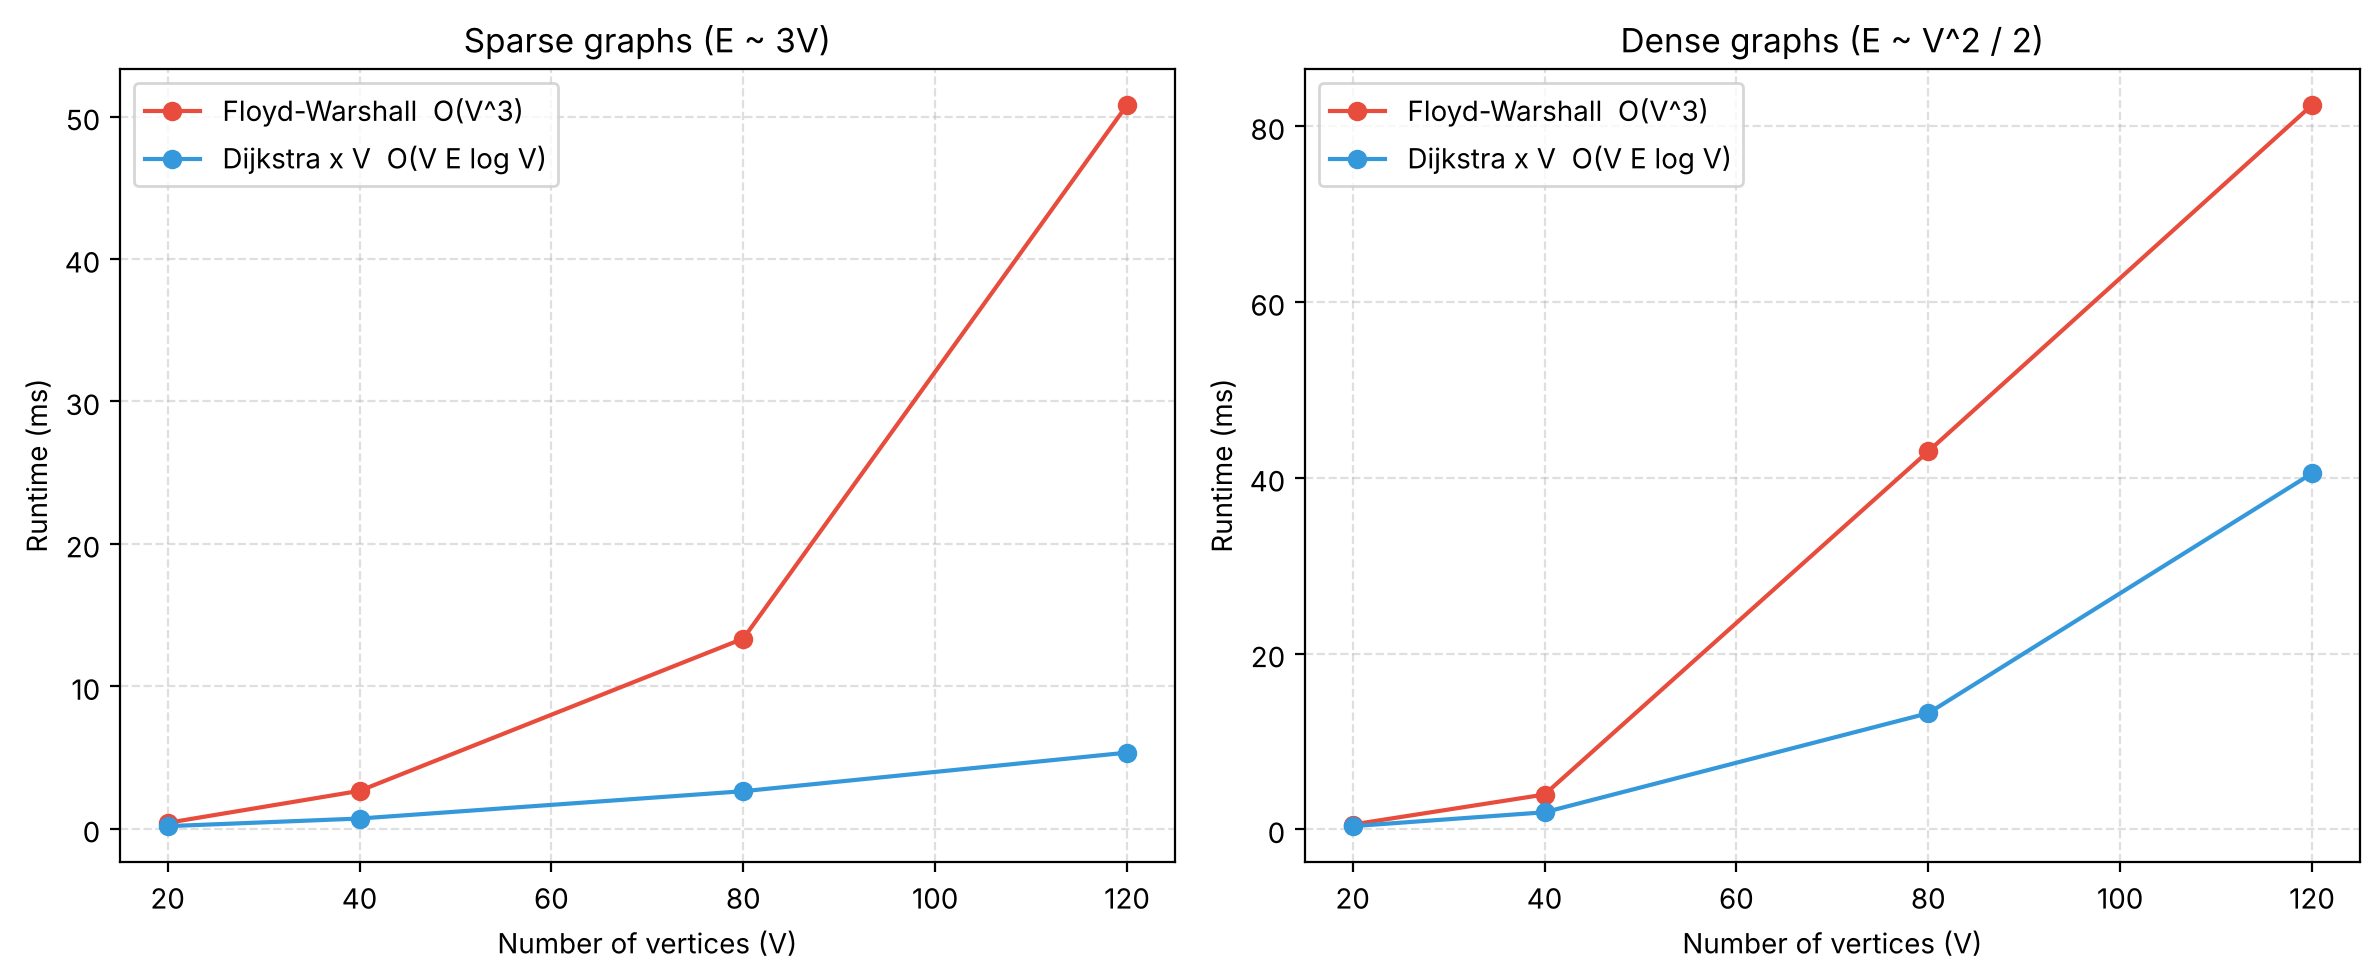

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(sizes, sparse_fw, marker='o', label='Floyd-Warshall  O(V^3)', color='#e74c3c')
axes[0].plot(sizes, sparse_dj, marker='o', label='Dijkstra x V  O(V E log V)', color='#3498db')
axes[0].set_title("Sparse graphs (E ~ 3V)")

axes[1].plot(sizes, dense_fw, marker='o', label='Floyd-Warshall  O(V^3)', color='#e74c3c')
axes[1].plot(sizes, dense_dj, marker='o', label='Dijkstra x V  O(V E log V)', color='#3498db')
axes[1].set_title("Dense graphs (E ~ V^2 / 2)")

for ax in axes:
    ax.set_xlabel("Number of vertices (V)")
    ax.set_ylabel("Runtime (ms)")
    ax.legend()
    ax.grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()


## Summary Table

| Approach                     | Time Complexity   | Space Complexity | Negative Edges? | Negative Cycle Detection? | Gives                |
|--------------------------------|---------------------|---------------------|-------------------|-----------------------------|------------------------|
| Floyd-Warshall                 | O(V^3)               | O(V^2)               | Yes               | Yes (`dist[i][i] < 0`)       | All-pairs distances + paths |
| Dijkstra from every vertex     | O(V · E log V)       | O(V^2) for output    | No                | No                           | All-pairs distances    |

Where `V` = number of vertices, `E` = number of edges.

**Notes:**
- Floyd-Warshall is **dynamic programming**: `dist[i][j]` after processing the first `k` vertices is the shortest path using only those as intermediates, and each step builds on the previous one.
- The **outermost loop must be `k`**. Putting `i` or `j` outside gives wrong answers, because the DP table for "intermediates up to `k`" must be fully computed before moving to `k + 1`.
- It is very short to implement and handles **negative edges**, which makes it a good choice for small graphs, when simplicity matters, or when negative weights are present.
- **Speed in practice:** in the experiment above, repeated Dijkstra was faster than Floyd-Warshall on both sparse *and* dense random graphs, even though the dense-graph bound suggests they should be close. The reason is that Floyd-Warshall always executes all `V^3` inner iterations, while Dijkstra's heap only does work for relaxations that actually succeed, which are far fewer than `E` with random weights. Results depend on the implementation language and the graph structure, so treat this as one data point, not a rule.
- For sparse graphs *with* negative edges, **Johnson's algorithm** combines Bellman-Ford and Dijkstra to beat `O(V^3)`.
- Distances can be stored in-place in a single matrix (as done here), so no extra `V x V` table per `k` is needed.
- A graph where `dist[i][j]` stays `INF` means `j` is **unreachable** from `i`.
